# Forecasting de demanda — LightGBM recursivo sin leakage

## tl;dr

Este notebook conserva **01/08/2017–15/08/2017 como test final**. La
elegibilidad se deriva en cada cutoff, tres ventanas anteriores se usan
para backtesting y selección del número de árboles, y el test se evalúa
una única vez después de fijar `best_iteration`.

Los resultados ejecutados, su comparación con la versión anterior y las
conclusiones aparecen al final del notebook.

## Contexto y método

### Supuestos clave

- Las promociones futuras (`onpromotion`) están disponibles antes del
  horizonte, como en el esquema de competencia Favorita.
- Sólo se utilizan feriados y días especiales programados. Los registros
  `type=Event`, potencialmente conocidos ex post, quedan fuera del modelo.
- Un error firmado positivo significa sobrepredicción y uno negativo,
  subpredicción.
- Las series nuevas se reportan como *cold-start* y no modifican el
  universo conocido en el cutoff.

In [1]:
from pathlib import Path
import gc
import sys

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.inspection import permutation_importance

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-whitegrid")

FINAL_TRAIN_END = pd.Timestamp("2017-07-31")
FINAL_TEST_START = pd.Timestamp("2017-08-01")
FINAL_TEST_END = pd.Timestamp("2017-08-15")
HORIZON_DAYS = 15
N_BACKTEST_WINDOWS = 3

print("Proyecto:", PROJECT_ROOT)
print("Test final:", FINAL_TEST_START.date(), "→", FINAL_TEST_END.date())
print(
    "Versiones validadas:",
    f"pandas={pd.__version__}",
    f"scikit-learn={sklearn.__version__}",
    f"lightgbm={lgb.__version__}",
)

Proyecto: C:\Users\keebs\OneDrive\Documentos\INTELIGENCIA ARTIFICIAL\MATERIAS 5S\PRACTICA PROFESIONALIZANTE 2\pf\bekantor-demand-intelligence
Test final: 2017-08-01 → 2017-08-15
Versiones validadas: pandas=3.0.0 scikit-learn=1.9.1 lightgbm=4.7.0


## Datos y contrato de features

In [2]:
from src.data.load_data import load_raw_data
from src.data.clean_data import minimal_cleaning
from src.features.model_features import (
    CATEGORICAL_FEATURES,
    MODEL_FEATURES,
    feature_availability_table,
)

datasets = minimal_cleaning(load_raw_data())
sales = datasets["sales"]

print(f"Ventas: {len(sales):,} filas")
print(sales["date"].min().date(), "→", sales["date"].max().date())
display(feature_availability_table())

Ventas: 3,000,888 filas
2013-01-01 → 2017-08-15


,feature,availability
0,store_nbr,Identidad conocida antes del horizonte.
1,family,Identidad conocida antes del horizonte.
2,year,Calendario determinístico.
3,month,Calendario determinístico.
4,day,Calendario determinístico.
5,day_of_week,Calendario determinístico.
6,week_of_year,Calendario determinístico.
7,is_weekend,Calendario determinístico.
8,onpromotion,Disponible sólo bajo el supuesto Favorita: el ...
9,city,Metadata estática conocida.


In [3]:
assert "is_event" not in MODEL_FEATURES
assert "event_count" not in MODEL_FEATURES
assert "scheduled_event_count" in MODEL_FEATURES
assert FINAL_TEST_START == FINAL_TRAIN_END + pd.Timedelta(days=1)

print("✓ Eventos potencialmente ex post excluidos")
print("✓ Sólo scheduled_event_count entra al modelo")
print("✓ Test final separado del desarrollo")

✓ Eventos potencialmente ex post excluidos
✓ Sólo scheduled_event_count entra al modelo
✓ Test final separado del desarrollo


### Verificación del universo corregido

In [4]:
from src.data.panel_diagnostics import (
    add_store_operation_flags,
    add_zero_taxonomy,
    build_modeling_panel,
)

legacy_sales, legacy_openings = add_store_operation_flags(sales)
legacy_sales = add_zero_taxonomy(legacy_sales)
legacy_series = (
    legacy_sales.loc[
        legacy_sales["tienda_operativa"]
        & legacy_sales["familia_surtida"],
        ["store_nbr", "family"],
    ]
    .drop_duplicates()
    .sort_values(["store_nbr", "family"])
    .reset_index(drop=True)
)

_, _, final_eligibility = build_modeling_panel(
    sales,
    cutoff=FINAL_TRAIN_END,
)
corrected_series = (
    final_eligibility.known_series[["store_nbr", "family"]]
    .sort_values(["store_nbr", "family"])
    .reset_index(drop=True)
)
corrected_openings = (
    final_eligibility.store_openings.set_index("store_nbr")["opening_date"]
)

universe_differences = len(
    legacy_series.merge(
        corrected_series,
        on=["store_nbr", "family"],
        how="outer",
        indicator=True,
    ).query("_merge != 'both'")
)
opening_differences = int(
    (
        legacy_openings.sort_index()
        != corrected_openings.reindex(legacy_openings.index)
    ).sum()
)

print("Diferencias de universo:", universe_differences)
print("Diferencias de aperturas:", opening_differences)
print("Series conocidas al 31/07/2017:", len(corrected_series))

assert universe_differences == 0
assert opening_differences == 0

del legacy_sales, legacy_series, corrected_series
gc.collect()

Diferencias de universo: 0
Diferencias de aperturas: 0
Series conocidas al 31/07/2017: 1729


21

## Rolling-origin backtesting y selección de árboles

In [5]:
from src.models.validation import rolling_origin_windows

backtest_windows = rolling_origin_windows(
    final_test_start=FINAL_TEST_START,
    n_windows=N_BACKTEST_WINDOWS,
    horizon_days=HORIZON_DAYS,
)
display(backtest_windows)

assert backtest_windows["validation_end"].max() < FINAL_TEST_START
assert (
    backtest_windows["validation_start"]
    == backtest_windows["train_end"] + pd.Timedelta(days=1)
).all()

,fold,train_end,validation_start,validation_end
0,1,2017-06-16,2017-06-17,2017-07-01
1,2,2017-07-01,2017-07-02,2017-07-16
2,3,2017-07-16,2017-07-17,2017-07-31


In [6]:
from src.models.experiment import run_backtest_fold

backtest_summaries = []
last_fold_result = None

for row in backtest_windows.itertuples(index=False):
    print(
        f"Fold {row.fold}: train hasta {row.train_end.date()} | "
        f"validación {row.validation_start.date()}–{row.validation_end.date()}"
    )
    fold_result = run_backtest_fold(
        datasets=datasets,
        train_end=row.train_end,
        validation_start=row.validation_start,
        validation_end=row.validation_end,
        fold=row.fold,
        # Techo técnico holgado: early stopping, no el cap, debe fijar
        # la cantidad de árboles. No es una búsqueda de hiperparámetros.
        max_estimators=2000,
        stopping_rounds=50,
    )
    backtest_summaries.append(fold_result["summary"])

    if row.fold == N_BACKTEST_WINDOWS:
        last_fold_result = fold_result
    else:
        del fold_result
        gc.collect()

backtest_results = pd.concat(backtest_summaries, ignore_index=True)
display(backtest_results.round(6))

Fold 1: train hasta 2017-06-16 | validación 2017-06-17–2017-07-01


Fold 2: train hasta 2017-07-01 | validación 2017-07-02–2017-07-16


Fold 3: train hasta 2017-07-16 | validación 2017-07-17–2017-07-31


C:\Users\keebs\AppData\Local\Temp\ipykernel_18448\2495825240.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(backtest_results.round(6))


,fold,train_end,validation_start,validation_end,model,best_iteration,known_series,cold_start_series,RMSLE,MAE,MSE_signed
0,1,2017-06-16,2017-06-17,2017-07-01,Seasonal baseline,NaN,1728,0,0.447856,76.631465,28.795689
1,1,2017-06-16,2017-06-17,2017-07-01,LightGBM recursive,1029.0,1728,0,0.388579,56.951156,10.794610
2,2,2017-07-01,2017-07-02,2017-07-16,Seasonal baseline,NaN,1728,1,0.427312,67.632701,-2.912112
3,2,2017-07-01,2017-07-02,2017-07-16,LightGBM recursive,369.0,1728,1,0.382500,57.939471,-3.637415
4,3,2017-07-16,2017-07-17,2017-07-31,Seasonal baseline,NaN,1729,0,0.452607,64.653889,7.082558
5,3,2017-07-16,2017-07-17,2017-07-31,LightGBM recursive,1336.0,1729,0,0.401833,56.770468,-20.543733


In [7]:
backtest_aggregate = (
    backtest_results.groupby("model", as_index=False)
    .agg(
        RMSLE_mean=("RMSLE", "mean"),
        RMSLE_std=("RMSLE", "std"),
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        signed_error_mean=("MSE_signed", "mean"),
        signed_error_std=("MSE_signed", "std"),
    )
)

selected_iterations = backtest_results.loc[
    backtest_results["model"].eq("LightGBM recursive"),
    "best_iteration",
].astype(int)
FINAL_N_ESTIMATORS = int(np.median(selected_iterations))

display(backtest_aggregate.round(6))
print("best_iteration por fold:", selected_iterations.tolist())
print("Árboles fijados para el modelo final:", FINAL_N_ESTIMATORS)

,model,RMSLE_mean,RMSLE_std,MAE_mean,MAE_std,signed_error_mean,signed_error_std
0,LightGBM recursive,0.390971,0.009886,57.220365,0.629283,-4.462179,15.685443
1,Seasonal baseline,0.442592,0.013444,69.639352,6.235829,10.988712,16.210790


best_iteration por fold: [1029, 369, 1336]
Árboles fijados para el modelo final: 1029


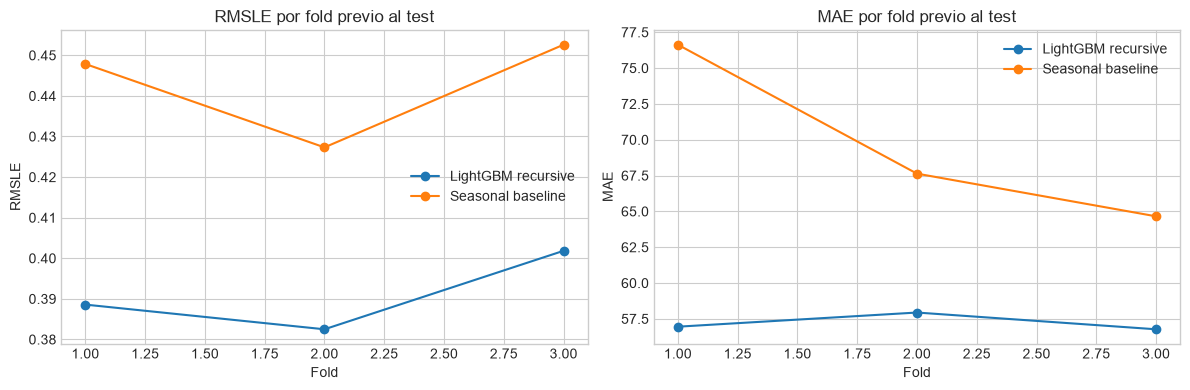

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name, group in backtest_results.groupby("model"):
    axes[0].plot(group["fold"], group["RMSLE"], marker="o", label=model_name)
    axes[1].plot(group["fold"], group["MAE"], marker="o", label=model_name)

axes[0].set(title="RMSLE por fold previo al test", xlabel="Fold", ylabel="RMSLE")
axes[1].set(title="MAE por fold previo al test", xlabel="Fold", ylabel="MAE")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

### Permutation importance fuera de entrenamiento

In [9]:
from src.features.model_features import add_lag_features, add_rolling_features
from src.models.categorical import apply_category_schema

last_prepared = last_fold_result["prepared"]
last_historical_features = add_rolling_features(
    add_lag_features(last_prepared["features_base"]),
    windows=(7, 14, 28),
)
permutation_frame = last_historical_features.loc[
    last_historical_features["date"].gt(
        backtest_windows.iloc[-1]["validation_start"]
    )
].copy()
if len(permutation_frame) > 50_000:
    permutation_frame = permutation_frame.sample(50_000, random_state=42)

X_permutation = permutation_frame[MODEL_FEATURES].copy()
X_permutation, permutation_unknown = apply_category_schema(
    X_permutation,
    last_fold_result["category_schema"],
)
assert permutation_unknown == {}

permutation = permutation_importance(
    last_fold_result["model"],
    X_permutation,
    np.log1p(permutation_frame["sales"]),
    scoring="neg_mean_squared_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1,
)
permutation_table = (
    pd.DataFrame(
        {
            "feature": MODEL_FEATURES,
            "importance_mean": permutation.importances_mean,
            "importance_std": permutation.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
display(permutation_table.head(15).round(6))

,feature,importance_mean,importance_std
0,rolling_mean_7,2.585854,0.026610
1,lag_1,0.731310,0.006497
2,onpromotion,0.538962,0.014229
3,family,0.174096,0.002494
4,lag_7,0.096703,0.000519
5,rolling_mean_28,0.029424,0.000559
6,rolling_mean_14,0.027410,0.000240
7,day_of_week,0.021124,0.000128
8,store_nbr,0.015368,0.000623
9,lag_14,0.011298,0.000067


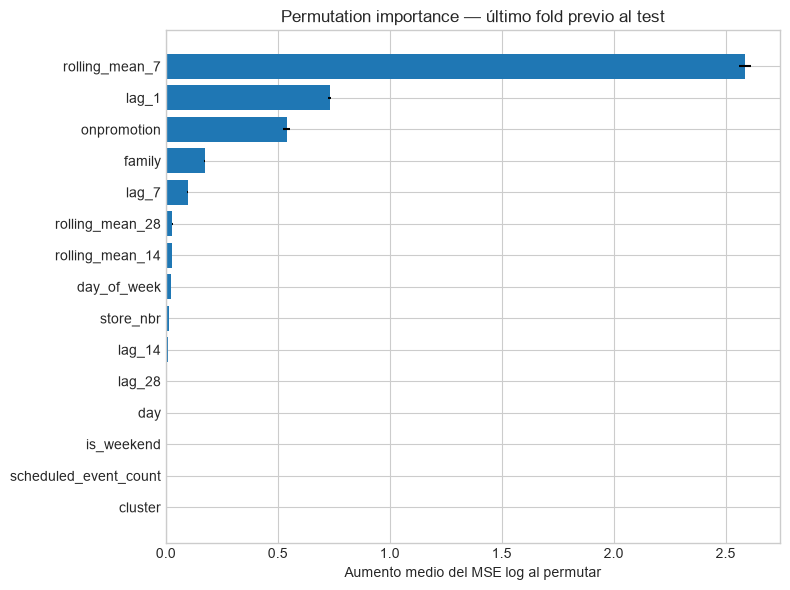

4848

In [10]:
permutation_plot = permutation_table.head(15).sort_values("importance_mean")
plt.figure(figsize=(8, 6))
plt.barh(
    permutation_plot["feature"],
    permutation_plot["importance_mean"],
    xerr=permutation_plot["importance_std"],
)
plt.title("Permutation importance — último fold previo al test")
plt.xlabel("Aumento medio del MSE log al permutar")
plt.tight_layout()
plt.show()

del last_historical_features, permutation_frame, X_permutation
del last_fold_result, last_prepared
gc.collect()

## Test final intocable

A partir de este punto `best_iteration` ya está fijado. Se reentrena con
toda la información disponible hasta el 31/07/2017 y se evalúa el test
01/08/2017–15/08/2017 una sola vez.

In [11]:
from src.models.experiment import run_final_test

final_result = run_final_test(
    datasets=datasets,
    train_end=FINAL_TRAIN_END,
    test_start=FINAL_TEST_START,
    test_end=FINAL_TEST_END,
    n_estimators=FINAL_N_ESTIMATORS,
)

final_summary = final_result["summary"]
display(final_summary.round(6))
print("Cold-start en test final:", len(final_result["prepared"]["cold_start_keys"]))
assert len(final_result["prepared"]["cold_start_keys"]) == 0

,model,RMSLE,MAE,MSE_signed
0,Seasonal baseline,0.536571,85.477984,4.223710
1,LightGBM recursive,0.398867,65.176282,16.999931


Cold-start en test final: 0


### Comparación con la versión anterior

In [12]:
previous_results = pd.DataFrame(
    [
        {"model": "Seasonal baseline", "previous_RMSLE": 0.536571, "previous_MAE": 85.477984},
        {"model": "LightGBM recursive", "previous_RMSLE": 0.405895, "previous_MAE": 70.298360},
    ]
)
final_comparison = final_summary.merge(previous_results, on="model", how="left")
final_comparison["delta_RMSLE"] = (
    final_comparison["RMSLE"] - final_comparison["previous_RMSLE"]
)
final_comparison["delta_MAE"] = (
    final_comparison["MAE"] - final_comparison["previous_MAE"]
)
display(final_comparison.round(6))

,model,RMSLE,MAE,MSE_signed,previous_RMSLE,previous_MAE,delta_RMSLE,delta_MAE
0,Seasonal baseline,0.536571,85.477984,4.223710,0.536571,85.477984,0.000000,-0.000000
1,LightGBM recursive,0.398867,65.176282,16.999931,0.405895,70.298360,-0.007028,-5.122078


## Diagnóstico del test final

In [13]:
from src.models.baseline import mae, mean_signed_error, rmsle

lgbm_eval = final_result["lgbm_eval"].copy()
baseline_eval = final_result["baseline_eval"].copy()
comparison_eval = lgbm_eval.merge(
    baseline_eval[["date", "store_nbr", "family", "pred_baseline"]],
    on=["date", "store_nbr", "family"],
    how="left",
    validate="one_to_one",
)
comparison_eval["horizon_day"] = (
    comparison_eval["date"] - FINAL_TEST_START
).dt.days + 1

daily_rows = []
for horizon_day, group in comparison_eval.groupby("horizon_day"):
    for model_name, prediction_col in [
        ("Seasonal baseline", "pred_baseline"),
        ("LightGBM recursive", "prediction"),
    ]:
        daily_rows.append(
            {
                "horizon_day": horizon_day,
                "model": model_name,
                "RMSLE": rmsle(group["sales"], group[prediction_col]),
                "MAE": mae(group["sales"], group[prediction_col]),
                "MSE_signed": mean_signed_error(
                    group["sales"], group[prediction_col]
                ),
            }
        )
daily_diagnostics = pd.DataFrame(daily_rows)
display(daily_diagnostics.round(6))

,horizon_day,model,RMSLE,MAE,MSE_signed
0,1,Seasonal baseline,0.528670,141.332613,-137.001396
1,1,LightGBM recursive,0.363640,62.019171,-18.432489
2,2,Seasonal baseline,0.541590,116.852812,-109.472908
3,2,LightGBM recursive,0.377887,60.420124,-22.151161
4,3,Seasonal baseline,0.529643,61.323535,-33.865337
5,3,LightGBM recursive,0.387646,59.116050,28.429480
6,4,Seasonal baseline,0.536580,65.981509,-17.684043
7,4,LightGBM recursive,0.409003,64.447827,17.488280
8,5,Seasonal baseline,0.475821,68.165595,10.101595
9,5,LightGBM recursive,0.371650,67.710648,41.840302


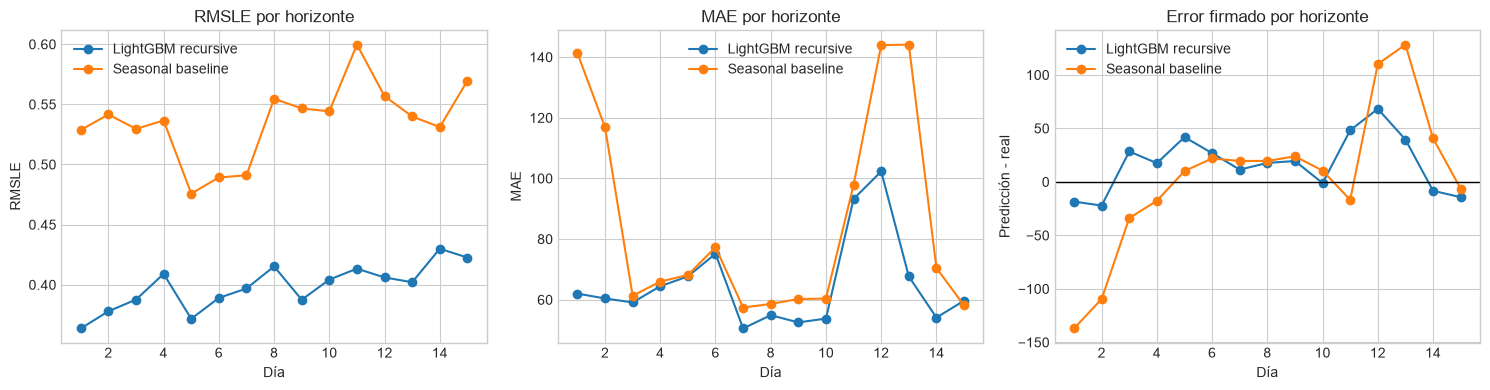

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for model_name, group in daily_diagnostics.groupby("model"):
    axes[0].plot(group["horizon_day"], group["RMSLE"], marker="o", label=model_name)
    axes[1].plot(group["horizon_day"], group["MAE"], marker="o", label=model_name)
    axes[2].plot(group["horizon_day"], group["MSE_signed"], marker="o", label=model_name)

axes[0].set(title="RMSLE por horizonte", xlabel="Día", ylabel="RMSLE")
axes[1].set(title="MAE por horizonte", xlabel="Día", ylabel="MAE")
axes[2].axhline(0, color="black", linewidth=1)
axes[2].set(title="Error firmado por horizonte", xlabel="Día", ylabel="Predicción - real")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

In [15]:
def grouped_metrics(data, group_col, prediction_col):
    rows = []
    for value, group in data.groupby(group_col, observed=True):
        rows.append(
            {
                group_col: value,
                "RMSLE": rmsle(group["sales"], group[prediction_col]),
                "MAE": mae(group["sales"], group[prediction_col]),
                "MSE_signed": mean_signed_error(
                    group["sales"], group[prediction_col]
                ),
                "n_obs": len(group),
            }
        )
    return pd.DataFrame(rows)

store_diagnostics = grouped_metrics(lgbm_eval, "store_nbr", "prediction")
family_diagnostics = grouped_metrics(lgbm_eval, "family", "prediction")

display(store_diagnostics.sort_values("RMSLE", ascending=False).head(15).round(6))
display(family_diagnostics.sort_values("RMSLE", ascending=False).head(15).round(6))

,store_nbr,RMSLE,MAE,MSE_signed,n_obs
18,19,0.519373,33.833958,4.963584,480
25,26,0.485813,33.994642,17.582857,495
21,22,0.480752,45.440271,-0.286917,480
24,25,0.478997,66.132355,-50.565870,480
35,36,0.465999,74.846121,-51.440356,480
13,14,0.456496,58.417927,1.073523,465
42,43,0.452252,66.386754,-17.201260,465
49,50,0.448643,94.728260,54.091917,480
47,48,0.447609,121.260593,66.048950,480
53,54,0.446750,82.002307,-33.260596,450


,family,RMSLE,MAE,MSE_signed,n_obs
21,LINGERIE,0.621487,3.943226,-1.814694,810
13,GROCERY II,0.611953,11.020476,2.486016,810
31,SCHOOL AND OFFICE SUPPLIES,0.590166,32.765856,-18.340836,810
19,LADIESWEAR,0.553913,4.329028,0.020147,660
6,CELEBRATION,0.538366,4.914413,-1.392988,810
23,MAGAZINES,0.538273,3.004416,-1.888699,810
14,HARDWARE,0.528198,1.061729,-0.382910,810
0,AUTOMOTIVE,0.503379,2.847796,-1.210833,810
15,HOME AND KITCHEN I,0.494198,11.302165,-6.949072,810
32,SEAFOOD,0.482667,4.288313,-1.060623,810


### Comparación por tipo de demanda ADI/CV²

In [16]:
from src.features.demand_classification import build_demand_profile

train_demand_profile = build_demand_profile(final_result["prepared"]["train"])
demand_eval = comparison_eval.merge(
    train_demand_profile[["store_nbr", "family", "tipo_demanda"]],
    on=["store_nbr", "family"],
    how="left",
    validate="many_to_one",
)
assert demand_eval["tipo_demanda"].notna().all()

demand_rows = []
for demand_type, group in demand_eval.groupby("tipo_demanda"):
    for model_name, prediction_col in [
        ("Seasonal baseline", "pred_baseline"),
        ("LightGBM recursive", "prediction"),
    ]:
        demand_rows.append(
            {
                "tipo_demanda": demand_type,
                "model": model_name,
                "RMSLE": rmsle(group["sales"], group[prediction_col]),
                "MAE": mae(group["sales"], group[prediction_col]),
                "MSE_signed": mean_signed_error(
                    group["sales"], group[prediction_col]
                ),
                "series": group[["store_nbr", "family"]].drop_duplicates().shape[0],
            }
        )
demand_diagnostics = pd.DataFrame(demand_rows)
display(demand_diagnostics.round(6))

,tipo_demanda,model,RMSLE,MAE,MSE_signed,series
0,Errática,Seasonal baseline,0.566929,71.485888,0.017733,288
1,Errática,LightGBM recursive,0.490973,58.518618,4.679070,288
2,Intermitente,Seasonal baseline,0.448745,18.201268,5.762417,409
3,Intermitente,LightGBM recursive,0.400906,15.737046,4.754918,409
4,Lumpy,Seasonal baseline,0.944629,16.528082,-11.487489,271
5,Lumpy,LightGBM recursive,0.545128,11.033182,-5.579386,271
6,Regular,Seasonal baseline,0.326346,151.484979,10.583401,761
7,Regular,LightGBM recursive,0.279342,113.547943,36.284574,761


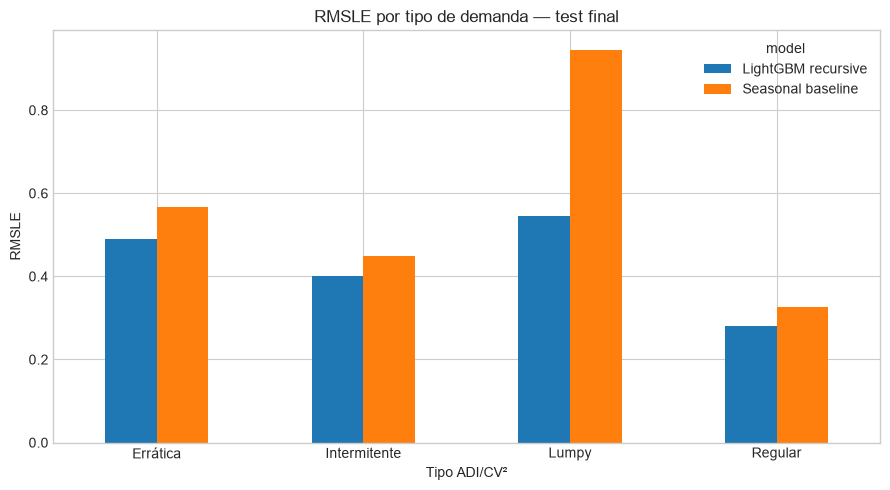

In [17]:
pivot = demand_diagnostics.pivot(
    index="tipo_demanda", columns="model", values="RMSLE"
)
pivot.plot(kind="bar", figsize=(9, 5))
plt.title("RMSLE por tipo de demanda — test final")
plt.xlabel("Tipo ADI/CV²")
plt.ylabel("RMSLE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Feature importance del modelo final

In [18]:
final_model = final_result["model"]
feature_importance = pd.DataFrame(
    {
        "feature": MODEL_FEATURES,
        "gain": final_model.booster_.feature_importance(importance_type="gain"),
        "splits": final_model.booster_.feature_importance(importance_type="split"),
    }
)
feature_importance["gain_pct"] = (
    feature_importance["gain"] / feature_importance["gain"].sum() * 100
)
feature_importance = feature_importance.sort_values(
    "gain", ascending=False
).reset_index(drop=True)
display(feature_importance.head(15).round(6))

print(
    "Gain y split describen el uso interno de features por LightGBM; "
    "no miden causalidad."
)

,feature,gain,splits,gain_pct
0,rolling_mean_7,1.069960e+08,4363,56.760514
1,lag_7,6.279189e+07,3541,33.310583
2,lag_1,7.266077e+06,4737,3.854594
3,rolling_mean_14,6.387322e+06,1660,3.388422
4,lag_14,1.224870e+06,2525,0.649783
5,family,1.154850e+06,10220,0.612639
6,is_new_year_closure,5.769036e+05,279,0.306043
7,lag_28,4.998494e+05,2549,0.265166
8,day_of_week,3.494229e+05,3617,0.185366
9,day,2.417808e+05,3966,0.128263


Gain y split describen el uso interno de features por LightGBM; no miden causalidad.


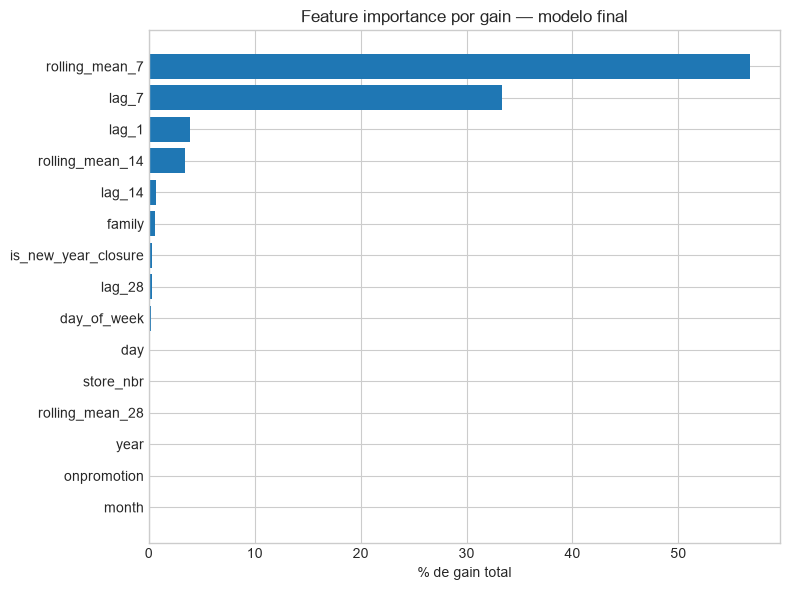

In [19]:
importance_plot = feature_importance.head(15).sort_values("gain_pct")
plt.figure(figsize=(8, 6))
plt.barh(importance_plot["feature"], importance_plot["gain_pct"])
plt.title("Feature importance por gain — modelo final")
plt.xlabel("% de gain total")
plt.tight_layout()
plt.show()

## Takeaways y controles finales

In [20]:
assert final_result["prepared"]["train"]["date"].max() == FINAL_TRAIN_END
assert comparison_eval["date"].min() == FINAL_TEST_START
assert comparison_eval["date"].max() == FINAL_TEST_END
assert comparison_eval["date"].nunique() == HORIZON_DAYS
assert comparison_eval["prediction"].notna().all()
assert np.isfinite(comparison_eval["prediction"]).all()
assert (comparison_eval["prediction"] >= 0).all()
assert set(final_result["category_schema"]) == set(CATEGORICAL_FEATURES)

print("RESULTADO FINAL")
display(final_comparison.round(6))
print("BACKTESTING")
display(backtest_aggregate.round(6))
print("Árboles seleccionados:", FINAL_N_ESTIMATORS)
print("Universo vs versión anterior: 0 diferencias")
print("Cold-start en test final: 0 series")
print("✓ Test final cubierto completamente y evaluado en forma recursiva")

RESULTADO FINAL


,model,RMSLE,MAE,MSE_signed,previous_RMSLE,previous_MAE,delta_RMSLE,delta_MAE
0,Seasonal baseline,0.536571,85.477984,4.223710,0.536571,85.477984,0.000000,-0.000000
1,LightGBM recursive,0.398867,65.176282,16.999931,0.405895,70.298360,-0.007028,-5.122078


BACKTESTING


,model,RMSLE_mean,RMSLE_std,MAE_mean,MAE_std,signed_error_mean,signed_error_std
0,LightGBM recursive,0.390971,0.009886,57.220365,0.629283,-4.462179,15.685443
1,Seasonal baseline,0.442592,0.013444,69.639352,6.235829,10.988712,16.210790


Árboles seleccionados: 1029
Universo vs versión anterior: 0 diferencias
Cold-start en test final: 0 series
✓ Test final cubierto completamente y evaluado en forma recursiva
